# 01. 5개국 인기 급상승 영상 탐색적 분석 (EDA)

- 데이터: 한국·미국·영국·일본·인도 인기 급상승 영상 국가별 200개, 총 1,000개 (업로드일 2025.09.18 ~ 10.18)
- 목적: 모델링 전에 국가·카테고리·해시태그·업로드 시점별 차이를 확인하고 변수 후보 선정
- 시간은 API 기준 UTC

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Noto Sans CJK KR"  # Windows는 "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

data = pd.read_excel("../data/YouTube_trending_5countries.xlsx")
data["viewCount"] = data["viewCount"].astype(int)
data["publishedAt"] = pd.to_datetime(data["publishedAt"], utc=True)
print(data.shape)
data.head(3)

(1000, 9)


,region,videoId,title,channelTitle,publishedAt,viewCount,likeCount,hashtags,category
0,KR,-kV4pRaqm0U,잠 안 자고 다이아 2만개 캐기,우정잉,2025-10-18 03:00:00+00:00,93173,1585,"우정잉, 트위치, 예능, 스트리머, 잉혐, 예민하네, 화났네, 잉토바이, 야랄, 무...",comedy
1,KR,PmX66n9ZxQA,요즘 애들은 점점 퇴화되고 있는 능력,주둥이방송,2025-10-16 09:11:46+00:00,371743,6908,NaN,entertainment
2,KR,rGD131gjLM8,픽셀 초비상,아구이뽀 A924,2025-10-17 06:00:47+00:00,133456,2646,NaN,entertainment


## 1. 국가별 평균 조회수·좋아요

In [2]:
country_summary = (
    data.groupby("region")
    .agg(avg_views=("viewCount", "mean"), avg_likes=("likeCount", "mean"), videos=("videoId", "nunique"))
    .round(0).sort_values("avg_views", ascending=False)
)
country_summary

,avg_views,avg_likes,videos
region,,,
IN,912624.0,22172.0,200
US,401465.0,18326.0,200
KR,367167.0,6149.0,200
GB,353411.0,14724.0,200
JP,163154.0,4899.0,200


## 2. 국가별 카테고리 분포

In [3]:
category_summary = (
    data.groupby(["region", "category"])
    .agg(total_views=("viewCount", "sum"), avg_views=("viewCount", "mean"), video_count=("videoId", "nunique"))
    .reset_index()
    .sort_values(["region", "total_views"], ascending=[True, False])
)
category_summary["rank_by_region"] = category_summary.groupby("region").cumcount() + 1
category_summary[category_summary["rank_by_region"] <= 3]

,region,category,total_views,avg_views,video_count,rank_by_region
3,GB,gaming,25324968,2.302270e+05,110,1
2,GB,film,19958445,2.851206e+06,7,2
4,GB,music,13525562,2.705112e+05,50,3
12,IN,music,117329167,1.485179e+06,79,1
11,IN,gaming,27979830,3.730644e+05,75,2
10,IN,film,15160523,2.165789e+06,7,3
19,JP,gaming,17566287,1.171086e+05,150,1
20,JP,music,8220335,5.480223e+05,15,2
17,JP,entertainment,4228470,1.566100e+05,27,3
26,KR,music,39393568,1.036673e+06,38,1


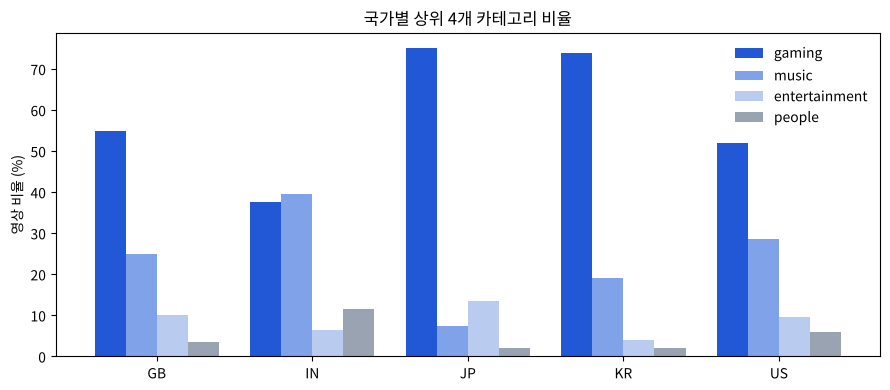

In [4]:
share = pd.crosstab(data["region"], data["category"], normalize="index").mul(100)
top_cats = data["category"].value_counts().index[:4]
ax = share[top_cats].plot(kind="bar", figsize=(9, 4), color=["#2257D6", "#7FA2E8", "#B9CBEF", "#9AA3B2"], width=0.8)
ax.set_ylabel("영상 비율 (%)"); ax.set_xlabel(""); ax.set_title("국가별 상위 4개 카테고리 비율")
ax.legend(title="", frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. 해시태그별 조회수

해시태그가 여러 개인 영상은 행이 여러 개로 늘어나므로, 영상 수는 `nunique`로 세고 조회수는 영상 기준으로 한 번만 더함

In [5]:
tags = data.dropna(subset=["hashtags"]).copy()
tags["hashtag"] = tags["hashtags"].str.split(",")
tags = tags.explode("hashtag")
tags["hashtag"] = tags["hashtag"].str.strip()
tags = tags[tags["hashtag"] != ""].drop_duplicates(["region", "videoId", "hashtag"])

hashtag_summary = (
    tags.groupby(["region", "hashtag"])
    .agg(video_count=("videoId", "nunique"), total_views=("viewCount", "sum"))
    .reset_index()
    .sort_values(["region", "video_count", "total_views"], ascending=[True, False, False])
)
print("해시태그가 있는 영상 비율:", round(data["hashtags"].notna().mean() * 100, 1), "%")
hashtag_summary.groupby("region").head(3)

해시태그가 있는 영상 비율: 80.7 %


,region,hashtag,video_count,total_views
2171,GB,roblox,21,5236326
1815,GB,minecraft,12,2040558
1410,GB,funny,10,2832051
4512,IN,minecraft,6,3144835
4093,IN,granny,6,2657778
4841,IN,roblox,6,784915
6317,JP,ゲーム実況,32,4406152
6312,JP,ゲーム,32,3922860
6876,JP,切り抜き,25,2240299
8062,KR,게임,21,2011409


## 4. 조회수 상위 10% 영상의 특징

상위 10% 영상과 전체 영상을 **영상 1개당 1번**씩 세어 비교 (해시태그로 행을 늘리기 전 데이터 사용)

In [6]:
threshold = data["viewCount"].quantile(0.9)
data["is_top10"] = data["viewCount"] >= threshold
data["weekday"] = data["publishedAt"].dt.day_name()
data["hour"] = data["publishedAt"].dt.hour
print(f"상위 10% 기준 조회수: {threshold:,.0f}회 / 영상 {data['is_top10'].sum()}개")

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = pd.crosstab(data["weekday"], data["is_top10"], normalize="columns").mul(100).reindex(order)
weekday.columns = ["나머지 90%", "상위 10%"]
weekday.round(1)

상위 10% 기준 조회수: 668,850회 / 영상 100개


,나머지 90%,상위 10%
weekday,,
Monday,0.2,6.0
Tuesday,1.4,5.0
Wednesday,3.6,13.0
Thursday,12.7,20.0
Friday,61.1,48.0
Saturday,20.8,7.0
Sunday,0.2,1.0


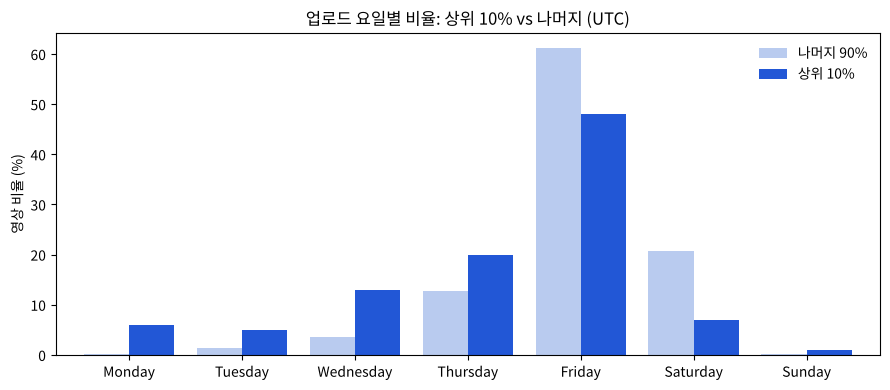

In [7]:
ax = weekday.plot(kind="bar", figsize=(9, 4), color=["#B9CBEF", "#2257D6"], width=0.8)
ax.set_ylabel("영상 비율 (%)"); ax.set_xlabel(""); ax.set_title("업로드 요일별 비율: 상위 10% vs 나머지 (UTC)")
ax.legend(frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [8]:
top = data[data["is_top10"]]
display(top["category"].value_counts().rename("상위 10% 영상 수").to_frame())
display(top["region"].value_counts(normalize=True).mul(100).round(1).rename("상위 10% 중 비율(%)").to_frame())

,상위 10% 영상 수
category,
music,33
gaming,32
film,11
entertainment,10
people,8
sports,5
travel,1


,상위 10% 중 비율(%)
region,
IN,38.0
US,23.0
GB,23.0
KR,8.0
JP,8.0


## 정리

- 국가마다 인기 카테고리가 다름: 영상 수 기준 일본·한국·영국·미국은 게임 비중이 크고, 인도는 음악이 조회수 1위
- 상위 10% 영상(조회수 668,850회 이상)의 38%가 인도 영상 → 국가 변수가 필요
- 해시태그가 있는 영상이 80.7%로, 해시태그 유무·개수(`has_hashtag`, `hashtag_count`)를 변수 후보로 선정
- 업로드 요일은 상위 10%와 나머지의 분포가 다르지만, 전체의 61%가 금요일 업로드라 **수집 시점에 가까운 요일에 영상이 몰리는 편향**이 있음
  → 업로드 요일 변수는 해석에 주의 필요 (10개국 데이터에서도 같은 현상을 확인해 [02_modeling](02_modeling.ipynb) 7-1에서 검증)
- 이후 10개국 2,000개 영상으로 확장해 바이럴 예측 모델링 진행